# Jalon 2 — inv-MR-Sort et inv-2-MR-Sort avec `lincs`

**Objectif.** (1) Apprendre un modèle MR-Sort unique avec l'heuristique de `lincs` (*weights, profiles, breed* de Sobrie et al.) ; (2) apprendre **deux** modèles MR-Sort en partitionnant en même temps le learning set (inv-2-MR-Sort).

**Heuristique proposée (alternance de type k-means / *clusterwise regression*).**

1. **Initialisation** : partition aléatoire, ou « graine par les erreurs » (on apprend un MR-Sort unique ; les objets mal classés forment la graine du segment 2).
2. **Étape M** : on apprend un MR-Sort par segment avec `lincs`.
3. **Étape E** : chaque objet est réaffecté au modèle qui l'explique le mieux, avec un critère lexicographique : (a) l'erreur $|h_{\text{prédit}} - h|$, puis (b) la **marge MR-Sort** $\min\big(C(x,b^{h-1})-\lambda,\ \lambda - C(x,b^{h})\big)$, où $C(x,b)=\sum_{i:x_i\ge b_i} w_i$.
4. On répète, on mémorise le meilleur état (taux d'objets expliqués par au moins un modèle), puis on fait un **polish** (ré-apprentissage plus long sur la partition finale). On utilise du **multi-start**.

**Références** : Sobrie, Mousseau & Pirlot (2013, 2019) pour l'heuristique lincs ; Späth (1979), DeSarbo & Cron (1988) pour la régression clusterwise ; Auriau, Belahcène, Malherbe & Mousseau (ADT 2024) pour l'apprentissage + segmentation de préférences hétérogènes.

In [30]:
# Installation (une seule fois). Sur Mac Apple Silicon, lincs 2.x fournit des wheels pour Python 3.11 à 3.14.
# %pip install lincs pandas numpy matplotlib scikit-learn pyyaml

In [31]:
import glob, os, re, time
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
import lincs, lincs.classification as C
from pathlib import Path
print("lincs", lincs.__version__)

# ---------------- Paramètres ----------------
DATA_DIR = Path("Datasets-Step2")         # dossier contenant problem.yml et les .csv (ex. .../Datasets-Step2/type_a/cr06_ca03)
FAST = True            # True = réglages rapides pour tester que tout tourne
LEARN_KW  = dict(max_seconds=0.5 if FAST else 1.5)   # budget lincs à chaque étape M
POLISH_KW = dict(max_seconds=2 if FAST else 8)       # budget lincs du polish final
N_ITER    = 5 if FAST else 20                        # itérations E/M max par run
INITS     = ("random", "errors") if FAST else ("random", "random", "errors", "random")  # multi-start
SEED = 0

lincs 2.0.2


## 1. Chargement des données (format `lincs` : `problem.yml` + CSV `name, critères..., category`)

In [32]:
def load_problem(path):
    # problem.yml est parsé à la main (le fichier fourni n'a pas la clé `kind` attendue par lincs 2.x)
    with open(path) as f:
        pb = yaml.safe_load(f)
    crits = pb["criteria"]
    assert all(c.get("preference_direction", "increasing") == "increasing" for c in crits), "critères à maximiser attendus"
    return {"criteria": [str(c["name"]) for c in crits],
            "categories": [str(c["name"]) for c in pb["ordered_categories"]]}   # de la pire à la meilleure

def load_dataset(csv_path, problem):
    df = pd.read_csv(csv_path)
    X = df[problem["criteria"]].to_numpy(float)
    y = df["category"].astype(str).map({c: i for i, c in enumerate(problem["categories"])}).to_numpy()
    assert not np.isnan(y.astype(float)).any(), "catégorie inconnue dans le CSV"
    return X, y.astype(int)

def parse_name(path):
    m = re.search(r"n(\d+)_rep(\d+)-(\d+)_noise(\d+)", os.path.basename(path))
    return dict(N=int(m[1]), rep=f"{m[2]}-{m[3]}", noise=int(m[4]) / 100) if m else {}


PB = load_problem(str(DATA_DIR / "type_a/cr06_ca03/problem.yml"))
FILES = sorted(glob.glob(str(DATA_DIR / "type_a/cr06_ca03/*.csv")))
print(PB); print(len(FILES), "fichiers :", [os.path.basename(f) for f in FILES])
P = len(PB["categories"])

{'criteria': ['Criterion 1', 'Criterion 2', 'Criterion 3', 'Criterion 4', 'Criterion 5', 'Criterion 6'], 'categories': ['1 (worst)', '2', '3 (best)']}
12 fichiers : ['n0300_rep50-50_noise00.csv', 'n0300_rep50-50_noise10.csv', 'n0300_rep75-25_noise00.csv', 'n0300_rep75-25_noise10.csv', 'n0600_rep50-50_noise00.csv', 'n0600_rep50-50_noise10.csv', 'n0600_rep75-25_noise00.csv', 'n0600_rep75-25_noise10.csv', 'n1200_rep50-50_noise00.csv', 'n1200_rep50-50_noise10.csv', 'n1200_rep75-25_noise00.csv', 'n1200_rep75-25_noise10.csv']


## 2. Briques MR-Sort autour de `lincs`

`learn_mrsort` lance l'heuristique WPB de lincs ; `predict` et `margins` recalculent la règle MR-Sort en numpy (en float32 comme lincs, ce qui donne exactement les mêmes affectations) pour pouvoir calculer des marges.

In [33]:
def make_problem(n, p):
    crits = [C.Criterion(f"c{i+1}", C.Criterion.RealValues(C.Criterion.PreferenceDirection.increasing, 0., 1.)) for i in range(n)]
    return C.Problem(crits, [C.Category(f"cat{h}") for h in range(p)])

def to_alts(problem, X, y=None):
    return C.Alternatives(problem, [
        C.Alternative(f"a{k}", [C.Performance(C.Performance.Real(float(v))) for v in X[k]],
                      None if y is None else int(y[k])) for k in range(len(X))])

def learn_mrsort(X, y, p, seed=0, models=9, max_seconds=5., patience=30):
    n = X.shape[1]
    problem = make_problem(n, p)
    pre = C.PreprocessedLearningSet(problem, to_alts(problem, X, y))
    mbl = C.LearnMrsortByWeightsProfilesBreed.ModelsBeingLearned(pre, models, int(seed))
    init = C.InitializeProfilesForProbabilisticMaximalDiscriminationPowerPerCriterion(pre, mbl)
    w = C.OptimizeWeightsUsingGlop(pre, mbl)
    prof = C.ImproveProfilesWithAccuracyHeuristicOnCpu(pre, mbl)
    breed = C.ReinitializeLeastAccurate(mbl, init, w, count=models // 2)
    term = C.TerminateWhenAny([C.TerminateAtAccuracy(mbl, len(X)), C.TerminateAfterSeconds(max_seconds),
                               C.TerminateAfterIterationsWithoutProgress(mbl, patience)])
    m = C.LearnMrsortByWeightsProfilesBreed(pre, mbl, init, w, prof, breed, term).perform()
    B = np.array([[av.real_thresholds.thresholds[h] for av in m.accepted_values] for h in range(p - 1)])
    W = np.array(m.sufficient_coalitions[0].weights.criterion_weights)
    # lincs normalise le seuil de majorité à 1 : on garde les poids bruts pour classer exactement comme lincs,
    # et on expose aussi les poids normalisés (somme = 1) et lambda correspondant pour l'interprétation.
    return {"profiles": B, "raw_weights": W, "weights": W / W.sum(), "lmbda": 1. / W.sum(),
            "_lincs": m, "_problem": problem}

def concordance(model, X):
    """C[k,h] = somme des poids des critères où x_k >= b^h"""
    # lincs stocke performances et profils en float32 : on compare dans la même précision
    X32 = np.asarray(X, dtype=np.float32)
    W32 = np.asarray(model["raw_weights"], dtype=np.float32)
    return np.stack([(X32 >= b.astype(np.float32)).astype(np.float32) @ W32 for b in model["profiles"]], axis=1).astype(float)

def predict(model, X):
    ok = concordance(model, X) >= 1.
    # règle pessimiste : nb de frontières franchies successivement
    return np.cumprod(ok, axis=1).sum(axis=1)

def margins(model, X, y):
    """Marge signée de x pour sa classe réelle y (échelle des poids normalisés) :
    > 0  => bien classé (et d'autant plus robuste que la marge est grande), <= 0 => mal classé."""
    Cn = (concordance(model, X) - 1.) / model["raw_weights"].sum()   # C(x,b^h) - lambda, normalisé
    p1 = Cn.shape[1]
    m = np.full(len(X), np.inf)
    low = y >= 1                                                    # doit franchir b^{y-1}
    m[low] = np.minimum(m[low], Cn[low, y[low] - 1] + 1e-12)
    up = y <= p1 - 1                                                # ne doit pas franchir b^{y}
    idx = np.where(up)[0]
    m[idx] = np.minimum(m[idx], -Cn[idx, y[idx]] - 1e-12)
    m[np.isinf(m)] = 1.
    return m

In [34]:
# Vérification : nos prédictions numpy == classify_alternatives de lincs
X, y = load_dataset(FILES[0], PB)
m = learn_mrsort(X, y, P, seed=1, **LEARN_KW)
alts = to_alts(m["_problem"], X); C.classify_alternatives(m["_problem"], m["_lincs"], alts)
lincs_pred = np.array([a.category_index for a in alts.alternatives])
print("accord numpy/lincs :", (lincs_pred == predict(m, X)).mean(), "| précision MR-Sort unique :", (predict(m, X) == y).mean().round(3))

accord numpy/lincs : 1.0 | précision MR-Sort unique : 0.793


## 3. Heuristique inv-2-MR-Sort

In [35]:
# ---------------------------------------------------------------- inv-2-MR-Sort
def assignment_scores(models, X, y):
    """Pour chaque modèle s : erreur |pred - y| et marge. Retourne (E, M) de forme (N, K)."""
    E = np.stack([np.abs(predict(m, X) - y) for m in models], axis=1)
    M = np.stack([margins(m, X, y) for m in models], axis=1)
    return E, M

def reassign(models, X, y):
    """Étape E : chaque objet va au modèle qui l'explique le mieux (erreur, puis marge)."""
    E, M = assignment_scores(models, X, y)
    key = E - 1e-3 * np.clip(M, -1, 1)          # tri lexicographique (erreur d'abord, marge ensuite)
    seg = np.argmin(key, axis=1)
    explained_by = (E == 0)                      # (N, K) booléen
    return seg, explained_by, E, M

def explained_rate(models, X, y):
    E, _ = assignment_scores(models, X, y)
    return (E.min(axis=1) == 0).mean()

def init_segments(X, y, p, K, how, rng, learn_kw):
    N = len(X)
    if how == "random":
        return rng.integers(K, size=N)
    if how == "errors":                          # graine = objets mal classés par un modèle unique
        m = learn_mrsort(X, y, p, seed=int(rng.integers(1e6)), **learn_kw)
        seg = (predict(m, X) != y).astype(int)
        return seg
    raise ValueError(how)

def learn_2_mrsort(X, y, p, K=2, init="errors", n_iter=15, share_ambiguous=True, min_frac=0.1,
                   seed=0, learn_kw=None, polish_kw=None, verbose=True):
    """Heuristique alternée (type k-means / clusterwise regression) pour inv-K-MR-Sort.
    - étape M : un MR-Sort appris par lincs sur chaque segment (pas d'élitisme : un modèle est toujours
      parfait sur ce qu'il explique déjà, garder l'ancien figerait la partition ; on mémorise le meilleur état)
    - étape E : réaffectation de chaque objet au modèle qui l'explique le mieux (erreur, puis marge)
    - share_ambiguous : un objet expliqué par plusieurs modèles est mis dans tous leurs learning sets
    - polish : à la fin, ré-apprentissage plus long de chaque modèle sur son segment final."""
    learn_kw = learn_kw or {}
    rng = np.random.default_rng(seed)
    N = len(X)
    seg = init_segments(X, y, p, K, init, rng, learn_kw)
    member = np.eye(K, dtype=bool)[seg]          # (N, K) appartenance (éventuellement multiple)
    models = [None] * K
    best, history = None, []
    for it in range(n_iter):
        # --- étape M
        for s in range(K):
            idx = np.where(member[:, s])[0]
            if len(idx) < max(10, min_frac * N):  # segment vide/trop petit : ré-ensemencement aléatoire
                idx = rng.choice(N, size=int(max(10, min_frac * N)), replace=False)
                models[s] = None
            models[s] = learn_mrsort(X[idx], y[idx], p, seed=int(rng.integers(1e6)), **learn_kw)
        # --- étape E
        new_seg, expl, E, M = reassign(models, X, y)
        score = (E.min(axis=1) == 0).mean()
        sizes = np.bincount(new_seg, minlength=K)
        history.append({"iter": it, "explained": score, "sizes": sizes.tolist(),
                        "ambiguous": float((expl.sum(1) > 1).mean()), "changed": float((new_seg != seg).mean())})
        if verbose:
            print(f"it {it:2d}  expliqués={score:.3f}  tailles={sizes.tolist()}  "
                  f"ambigus={history[-1]['ambiguous']:.2f}  changements={history[-1]['changed']:.3f}")
        if best is None or score > best["score"]:
            best = {"score": score, "models": list(models), "seg": new_seg.copy(), "explained_by": expl}
        new_member = np.eye(K, dtype=bool)[new_seg]
        if share_ambiguous:
            new_member |= expl & (expl.sum(1, keepdims=True) > 1)
        if (new_member == member).all():
            break
        member, seg = new_member, new_seg
    # --- polish : ré-apprentissage long sur les segments finaux
    if polish_kw:
        seg, expl = best["seg"], best["explained_by"]
        member = np.eye(K, dtype=bool)[seg] | (expl & (expl.sum(1, keepdims=True) > 1) if share_ambiguous else False)
        models = []
        for s in range(K):
            idx = np.where(member[:, s])[0]
            new = learn_mrsort(X[idx], y[idx], p, seed=int(rng.integers(1e6)), **polish_kw)
            old = best["models"][s]
            models.append(new if (predict(new, X[idx]) == y[idx]).mean() >= (predict(old, X[idx]) == y[idx]).mean() else old)
        new_seg, expl, E, M = reassign(models, X, y)
        score = (E.min(axis=1) == 0).mean()
        if verbose:
            print(f"polish   expliqués={score:.3f}  tailles={np.bincount(new_seg, minlength=K).tolist()}")
        if score >= best["score"]:
            best.update(score=score, models=models, seg=new_seg, explained_by=expl)
    best["history"] = pd.DataFrame(history)
    return best

def multistart(X, y, p, K=2, inits=("errors", "random", "random", "random"), seed=0, **kw):
    runs = []
    for r, how in enumerate(inits):
        res = learn_2_mrsort(X, y, p, K=K, init=how, seed=seed + r, **kw)
        res["init"] = how
        runs.append(res)
    return max(runs, key=lambda r: r["score"]), runs

## 4. Un jeu de données : MR-Sort unique vs deux MR-Sort

In [36]:
FILE = [f for f in FILES if "n0600_rep50-50_noise00" in f][0] if any("n0600_rep50-50_noise00" in f for f in FILES) else FILES[0]
X, y = load_dataset(FILE, PB)
print(os.path.basename(FILE), parse_name(FILE), "| classes :", np.bincount(y))

t = time.time()
single = learn_mrsort(X, y, P, seed=SEED, **POLISH_KW)
print(f"MR-Sort unique : {(predict(single, X) == y).mean():.3f}  ({time.time()-t:.0f}s)")

t = time.time()
best, runs = multistart(X, y, P, K=2, inits=INITS, seed=SEED, n_iter=N_ITER,
                        learn_kw=LEARN_KW, polish_kw=POLISH_KW, share_ambiguous=False, verbose=False)
print(f"2-MR-Sort     : {best['score']:.3f}  (meilleur run : init={best['init']}, {time.time()-t:.0f}s)")
for r in runs: print(f"   run init={r['init']:7s} -> {r['score']:.3f}")

n0600_rep50-50_noise00.csv {'N': 600, 'rep': '50-50', 'noise': 0.0} | classes : [ 61 193 346]
MR-Sort unique : 0.743  (2s)
2-MR-Sort     : 0.942  (meilleur run : init=random, 17s)
   run init=random  -> 0.942
   run init=errors  -> 0.932


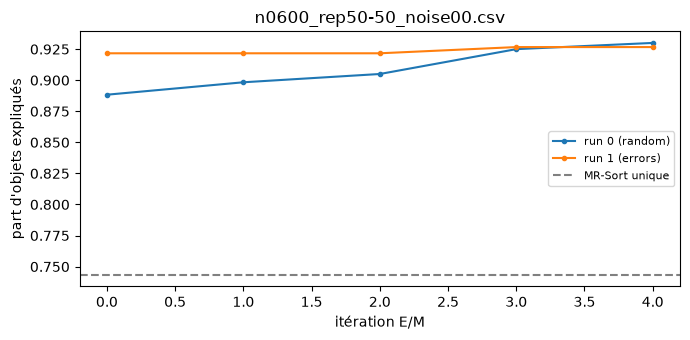

In [37]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, r in enumerate(runs):
    ax.plot(r["history"]["iter"], r["history"]["explained"], marker="o", ms=3, label=f"run {i} ({r['init']})")
ax.axhline((predict(single, X) == y).mean(), ls="--", c="grey", label="MR-Sort unique")
ax.set_xlabel("itération E/M"); ax.set_ylabel("part d'objets expliqués"); ax.legend(fontsize=8); ax.set_title(os.path.basename(FILE))
plt.tight_layout(); plt.show()

In [38]:
def show_model(m, name):
    df = pd.DataFrame(m["profiles"], columns=PB["criteria"], index=[f"b{h+1}" for h in range(len(m["profiles"]))])
    df.loc["poids"] = m["weights"]
    print(f"--- {name}   lambda = {m['lmbda']:.3f}"); display(df.round(3))

for s, m_ in enumerate(best["models"]):
    show_model(m_, f"segment {s+1} ({(best['seg']==s).sum()} objets)")
amb = (best["explained_by"].sum(1) > 1).mean()
print(f"objets expliqués par les 2 modèles : {amb:.2%} | par aucun : {(best['explained_by'].sum(1)==0).mean():.2%}")

--- segment 1 (247 objets)   lambda = 0.571


,Criterion 1,Criterion 2,Criterion 3,Criterion 4,Criterion 5,Criterion 6
b1,0.192,0.827,0.214,0.310,0.000,0.146
b2,0.490,0.996,0.688,0.310,0.295,0.176
poids,0.143,0.143,0.143,0.143,0.143,0.286


--- segment 2 (353 objets)   lambda = 0.571


,Criterion 1,Criterion 2,Criterion 3,Criterion 4,Criterion 5,Criterion 6
b1,0.014,0.085,0.306,0.421,0.077,0.170
b2,0.118,0.259,0.579,0.483,0.077,0.355
poids,0.143,0.286,0.143,0.143,0.143,0.143


objets expliqués par les 2 modèles : 40.67% | par aucun : 5.83%


## 5. Validation sur données synthétiques (segments connus)

Les CSV fournis ne disent pas à quel segment appartient chaque objet. Pour mesurer si l'heuristique **retrouve la segmentation**, on génère deux MR-Sort de vérité terrain, on étiquette une part `rep` des objets avec le modèle 1 et le reste avec le modèle 2, on ajoute éventuellement du bruit, puis on mesure l'**ARI** (*adjusted Rand index*) entre la partition trouvée et la vraie. Les objets ambigus (bien classés par les deux vrais modèles) rendent l'ARI pessimiste ; on le calcule donc aussi sur les seuls objets non ambigus.

In [39]:
def random_mrsort(n, p, rng):
    w = rng.dirichlet(np.ones(n))
    lam = rng.uniform(0.5, 0.8)
    B = np.sort(rng.uniform(0.15, 0.85, size=(p - 1, n)), axis=0)   # profils ordonnés b1 <= b2 ...
    W = w / lam                                                      # convention lincs : seuil = 1
    return {"profiles": B, "raw_weights": W, "weights": w, "lmbda": lam}

def make_two_segment_data(N, n, p, rep=0.5, noise=0.0, seed=0):
    rng = np.random.default_rng(seed)
    M1, M2 = random_mrsort(n, p, rng), random_mrsort(n, p, rng)
    X = rng.uniform(0, 1, size=(N, n))
    seg = (rng.uniform(size=N) >= rep).astype(int)
    y = np.where(seg == 0, predict(M1, X), predict(M2, X))
    flip = rng.uniform(size=N) < noise
    y[flip] = rng.integers(p, size=flip.sum())
    ambiguous = predict(M1, X) == predict(M2, X)
    return X, y, seg, ambiguous, (M1, M2)

rows = []
for rep in [0.5, 0.75]:
    for rs in range(1 if FAST else 3):
        Xs, ys, seg_true, amb_true, _ = make_two_segment_data(600, len(PB["criteria"]), P, rep=rep, seed=rs)
        base = (predict(learn_mrsort(Xs, ys, P, seed=rs, **POLISH_KW), Xs) == ys).mean()
        b, _ = multistart(Xs, ys, P, inits=INITS, seed=rs, n_iter=N_ITER, learn_kw=LEARN_KW,
                          polish_kw=POLISH_KW, share_ambiguous=False, verbose=False)
        na = ~amb_true
        rows.append(dict(rep=rep, seed=rs, single=base, two=b["score"],
                         ARI=adjusted_rand_score(seg_true, b["seg"]),
                         ARI_non_ambigus=adjusted_rand_score(seg_true[na], b["seg"][na]),
                         part_ambigus=amb_true.mean()))
        print(rows[-1])
synth = pd.DataFrame(rows); display(synth.groupby("rep").mean(numeric_only=True).round(3))

{'rep': 0.5, 'seed': 0, 'single': np.float64(0.8633333333333333), 'two': np.float64(0.985), 'ARI': -0.0015323102514264583, 'ARI_non_ambigus': -0.0039161100665842585, 'part_ambigus': np.float64(0.6816666666666666)}
{'rep': 0.75, 'seed': 0, 'single': np.float64(0.9083333333333333), 'two': np.float64(0.9933333333333333), 'ARI': 0.06524163948069549, 'ARI_non_ambigus': 0.34183413667785073, 'part_ambigus': np.float64(0.6816666666666666)}


,seed,single,two,ARI,ARI_non_ambigus,part_ambigus
rep,,,,,,
0.50,0.0,0.863,0.985,-0.002,-0.004,0.682
0.75,0.0,0.908,0.993,0.065,0.342,0.682


**Lecture des résultats (constat de nos premiers tests).** Le score « expliqué » monte vite au-delà de 95 %, mais l'ARI reste souvent faible (≈ 0 à 0,5 selon l'instance). Le problème est **mal identifié** : un MR-Sort a assez de paramètres (2 profils × n + n poids) pour « éponger » les objets résiduels, donc beaucoup de partitions expliquent presque tout le learning set sans correspondre aux vrais segments. Plus les deux vrais modèles sont proches (forte `part_ambigus`), plus c'est marqué. C'est un point à discuter dans le rendu : le critère « expliqué par au moins un modèle » ne suffit pas, et il faut le compléter (jeu test, régularisation, critère de parcimonie, contrainte de taille des segments…).

## 6. Tous les jeux de données : apprentissage / test

Le score « expliqué par au moins un des deux modèles » est **optimiste** : avec deux modèles, un objet bruité a plus de chances d'être expliqué par hasard. On l'évalue donc aussi sur un **jeu test** (80/20) et on compare au MR-Sort unique. Pour classer un objet *nouveau* dont on ne connaît pas le segment, il faudra une règle d'agrégation (piste : le modèle le plus confiant au sens de la marge, ou une estimation du segment).

In [40]:
def evaluate_file(path, test_frac=0.2, seed=0):
    X, y = load_dataset(path, PB)
    rng = np.random.default_rng(seed); perm = rng.permutation(len(X)); nt = int(test_frac * len(X))
    te, tr = perm[:nt], perm[nt:]
    t = time.time()
    single = learn_mrsort(X[tr], y[tr], P, seed=seed, **POLISH_KW)
    b, _ = multistart(X[tr], y[tr], P, inits=INITS, seed=seed, n_iter=N_ITER, learn_kw=LEARN_KW,
                      polish_kw=POLISH_KW, share_ambiguous=False, verbose=False)
    return dict(file=os.path.basename(path), **parse_name(path),
                single_train=(predict(single, X[tr]) == y[tr]).mean(), single_test=(predict(single, X[te]) == y[te]).mean(),
                two_train=b["score"], two_test=explained_rate(b["models"], X[te], y[te]),
                seg_sizes=np.bincount(b["seg"], minlength=2).tolist(), seconds=round(time.time() - t))

results = []
for f in (FILES[:2] if FAST else FILES):
    results.append(evaluate_file(f)); print(results[-1])
res = pd.DataFrame(results); display(res.round(3))
res.to_csv("resultats_jalon2.csv", index=False)

{'file': 'n0300_rep50-50_noise00.csv', 'N': 300, 'rep': '50-50', 'noise': 0.0, 'single_train': np.float64(0.7916666666666666), 'single_test': np.float64(0.6833333333333333), 'two_train': np.float64(0.9791666666666666), 'two_test': np.float64(0.8666666666666667), 'seg_sizes': [143, 97], 'seconds': 12}
{'file': 'n0300_rep50-50_noise10.csv', 'N': 300, 'rep': '50-50', 'noise': 0.1, 'single_train': np.float64(0.7375), 'single_test': np.float64(0.5666666666666667), 'two_train': np.float64(0.9541666666666667), 'two_test': np.float64(0.7166666666666667), 'seg_sizes': [104, 136], 'seconds': 12}


,file,N,rep,noise,single_train,single_test,two_train,two_test,seg_sizes,seconds
0,n0300_rep50-50_noise00.csv,300,50-50,0.0,0.792,0.683,0.979,0.867,"[143, 97]",12
1,n0300_rep50-50_noise10.csv,300,50-50,0.1,0.738,0.567,0.954,0.717,"[104, 136]",12


## 7. Pistes d'amélioration

- **Raffinement à la Späth** : après convergence, tester le déplacement individuel des objets mal expliqués vers l'autre segment et accepter si le score global s'améliore.
- **Version douce (EM, DeSarbo & Cron)** : pondérer les objets par une probabilité d'appartenance fonction de la marge, plutôt qu'une affectation dure.
- **Budget lincs** : plus de temps par étape M réduit le bruit de la trajectoire (lincs est stochastique) mais coûte cher ; un compromis consiste à augmenter le budget au fil des itérations.
- **Identifiabilité** : pénaliser les solutions où un modèle n'explique qu'un « résidu » (ex. maximiser la précision du *pire* segment, ou exiger que chaque modèle généralise sur un jeu de validation de son segment).
- **Choix de K** : comparer K = 1, 2, 3 sur jeu test, pour vérifier que l'hypothèse des 2 segments est soutenue par les données.
- **Jalon 3** : séparer les données de A de celles de l'agent malicieux, c'est exactement inv-2-MR-Sort avec rep = 50-50.